# Plate Reader Training — YOLO26s

Trains a YOLO26s character detector on cropped licence plates (`bangla-plate-reading`, 103 classes) and evaluates it on the test split, both per character (mAP) and per plate (the plate text built from the detections).

**Settings changed from the Ultralytics defaults**

| Setting | Value | Reason |
|---|---|---|
| `imgsz` | 320 | the input is one plate crop, not a full frame |
| `fliplr` | 0.0 | a mirrored character is a different or invalid character |
| `mosaic` | 0.0 | the reader always sees one plate; mosaic shrinks characters to a quarter |
| `epochs` | 150, no early stopping | |

**Setup (Kaggle notebook)**
1. Add `bangla-plate-reading` as an input.
2. Accelerator: **GPU**.
3. Run All.

In [1]:
%pip install -q ultralytics==8.4.46

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.2/1.2 MB 16.3 MB/s eta 0:00:0000:0100:01
Note: you may need to restart the kernel to use updated packages.


## Configuration

In [2]:
EXPERIMENT = "yolo26s-reader"

EXPERIMENTS = {
    "yolo26n-reader": {"model": "yolo26n.pt", "batch": 64},
    "yolo26s-reader": {"model": "yolo26s.pt", "batch": 64},
}
EPOCHS = 150
IMGSZ = 320
SEED = 0

## Setup

In [3]:
import json
import shutil
from pathlib import Path

import pandas as pd
import torch
from ultralytics import YOLO

config = EXPERIMENTS[EXPERIMENT]
WORK = Path("/kaggle/working")
INPUT = Path("/kaggle/input")
RUNS = WORK / "runs"

gpus = torch.cuda.device_count()
DEVICE = ",".join(str(i) for i in range(gpus)) if gpus else "cpu"

# copy the dataset so Ultralytics can write its label cache
DATA = WORK / "plate-reading"
if not DATA.exists():
    shutil.copytree(next(p for p in INPUT.rglob("bangla-plate-reading") if p.is_dir()), DATA)
DATA_YAML = DATA / "data.yaml"
RUN = RUNS / EXPERIMENT
WEIGHTS = RUN / "weights" / "best.pt"
CLASSES = json.loads((DATA / "classes.json").read_text(encoding="utf-8"))

print(f"Experiment: {EXPERIMENT}  {config}\nDevice: {DEVICE}")
for split in ("train", "val", "test"):
    print(f"{split:5} {len(list((DATA / 'images' / split).iterdir())):6d} crops")

Creating new Ultralytics Settings v0.0.6 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/quickstart/#ultralytics-settings.
Experiment: yolo26s-reader  {'model': 'yolo26s.pt', 'batch': 64}
Device: 0,1
train   7859 crops
val     1736 crops
test     939 crops


## Train

In [4]:
YOLO(config["model"]).train(
    data=str(DATA_YAML), imgsz=IMGSZ, epochs=EPOCHS, batch=config["batch"], patience=0,
    fliplr=0.0, mosaic=0.0,
    device=DEVICE, seed=SEED, project=str(RUNS), name=EXPERIMENT, exist_ok=True,
)
print("Weights:", WEIGHTS)

New https://pypi.org/project/ultralytics/8.4.182 available 😃 Update with 'pip install -U ultralytics'
Ultralytics 8.4.46 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14912MiB)
                                                       CUDA:1 (Tesla T4, 14912MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=64, bgr=0.0, box=7.5, cache=False, cfg=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/kaggle/working/plate-reading/data.yaml, degrees=0.0, deterministic=True, device=0,1, dfl=1.5, dnn=False, dropout=0.0, dynamic=False, embed=None, end2end=None, epochs=150, erasing=0.4, exist_ok=True, fliplr=0.0, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, half=False, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=320, int8=False, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300,

/usr/local/lib/python3.13/dist-packages/ultralytics/utils/metrics.py:75: UserWarning: Specified kernel cache directory could not be created! This disables kernel caching. Specified directory is /root/.cache/torch/kernels. This warning will appear only once per process. (Triggered internally at /pytorch/aten/src/ATen/native/cuda/jit_utils.cpp:1505.)
  inter = (torch.min(a2, b2) - torch.max(a1, b1)).clamp_(0).prod(2)


                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 14/14 1.2s/it 16.7s0.3s
                   all       1736      15121      0.687      0.145      0.156      0.103

      Epoch    GPU_mem   box_loss   cls_loss   dfl_loss  Instances       Size
      2/150      3.23G      1.102      1.055    0.00961        230        320: 100% ━━━━━━━━━━━━ 123/123 2.1it/s 59.8s0.5ss
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 14/14 3.3it/s 4.3s0.3s
                   all       1736      15121      0.572      0.423      0.442      0.308

      Epoch    GPU_mem   box_loss   cls_loss   dfl_loss  Instances       Size
      3/150      3.23G      1.096      0.697   0.009554        223        320: 100% ━━━━━━━━━━━━ 123/123 2.1it/s 59.6s0.5ss
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 14/14 3.3it/s 4.2s0.3s
                   all

## Training curves

Epochs: 150  best epoch 148: mAP@0.5 0.9744  mAP@0.5:0.95 0.7919


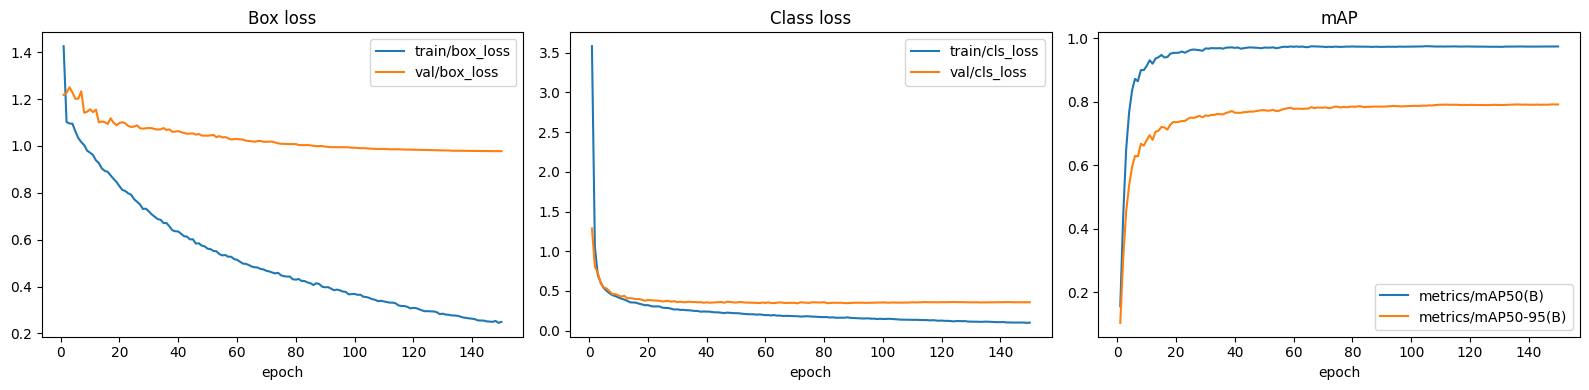

In [5]:
import matplotlib.pyplot as plt

df = pd.read_csv(RUN / "results.csv")
df.columns = df.columns.str.strip()
best = df.loc[df["metrics/mAP50-95(B)"].idxmax()]
print(f"Epochs: {len(df)}  best epoch {int(best['epoch'])}: "
      f"mAP@0.5 {best['metrics/mAP50(B)']:.4f}  mAP@0.5:0.95 {best['metrics/mAP50-95(B)']:.4f}")

fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for keys, ax, title in [
    (("train/box_loss", "val/box_loss"), axes[0], "Box loss"),
    (("train/cls_loss", "val/cls_loss"), axes[1], "Class loss"),
    (("metrics/mAP50(B)", "metrics/mAP50-95(B)"), axes[2], "mAP"),
]:
    for key in keys:
        ax.plot(df["epoch"], df[key], label=key)
    ax.set_title(title)
    ax.set_xlabel("epoch")
    ax.legend()
plt.tight_layout()
plt.show()

## Test: characters

mAP on the test split, per class and by class kind.

In [6]:
model = YOLO(WEIGHTS)
metrics = model.val(data=str(DATA_YAML), split="test", imgsz=IMGSZ, batch=config["batch"], device=DEVICE,
                    project=str(RUNS), name=f"{EXPERIMENT}-test", exist_ok=True, plots=False)
print(f"Test  P {metrics.box.mp:.4f}  R {metrics.box.mr:.4f}  "
      f"mAP@0.5 {metrics.box.map50:.4f}  mAP@0.5:0.95 {metrics.box.map:.4f}")

per_class = pd.DataFrame({
    "class": [CLASSES[i]["name"] for i in metrics.box.ap_class_index],
    "kind": [CLASSES[i]["kind"] for i in metrics.box.ap_class_index],
    "mAP50": metrics.box.ap50,
    "mAP50-95": metrics.box.ap,
})
print(per_class.groupby("kind")[["mAP50", "mAP50-95"]].mean().round(4))
print("\nWeakest classes:")
print(per_class.sort_values("mAP50").head(10).round(4).to_string(index=False))

Ultralytics 8.4.46 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14912MiB)
                                                       CUDA:1 (Tesla T4, 14912MiB)
YOLO26s summary (fused): 122 layers, 9,505,041 parameters, 0 gradients, 20.7 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 994.4±146.6 MB/s, size: 38.0 KB)
val: Scanning /kaggle/working/plate-reading/labels/test... 939 images, 1 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 939/939 1.3Kit/s 0.7s0.0ss
val: New cache created: /kaggle/working/plate-reading/labels/test.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 15/15 3.5it/s 4.3s0.3s
                   all        939       8213      0.974       0.93      0.965      0.774
                     0        341        433      0.983      0.954      0.975      0.664
                     1        617       1062      0.995      0.956      0.984      0.649
                     2        404        510      0.996

## Test: plate text

The detections of each crop are turned into plate text: boxes are split into a top and a bottom line at the largest vertical gap, each line is read left to right, and six digits are written as `12-3456`. The labels go through the same function, so the comparison does not depend on formatting.

- **Plate accuracy**: share of plates whose full text is correct.
- **Character error rate (CER)**: edit distance between predicted and true text, divided by the length of the true text.

In [7]:
BANGLA = [c["bangla"] for c in CLASSES]
KIND = [c["kind"] for c in CLASSES]


def plate_text(boxes):
    # boxes: (class, x_center, y_center, width, height), normalised
    if not boxes:
        return ""
    boxes = sorted(boxes, key=lambda b: b[2])
    lines = [boxes]
    if len(boxes) > 1:
        gaps = [boxes[i + 1][2] - boxes[i][2] for i in range(len(boxes) - 1)]
        split = max(range(len(gaps)), key=gaps.__getitem__)
        median_h = sorted(b[4] for b in boxes)[len(boxes) // 2]
        if gaps[split] > 0.5 * median_h:
            lines = [boxes[:split + 1], boxes[split + 1:]]
    out = []
    for line in lines:
        line = sorted(line, key=lambda b: b[1])
        tokens = [BANGLA[int(b[0])] for b in line]
        if all(KIND[int(b[0])] == "digit" for b in line):
            digits = "".join(tokens)
            out.append(f"{digits[:2]}-{digits[2:]}" if len(digits) == 6 else digits)
        else:
            # keep runs of digits together: ["ঢাকা", "১", "২"] -> "ঢাকা ১২"
            words = []
            for b, token in zip(line, tokens):
                if words and KIND[int(b[0])] == "digit" and words[-1][0] == "digit":
                    words[-1][1] += token
                else:
                    words.append([KIND[int(b[0])], token])
            out.append(" ".join(w for _, w in words))
    return " ".join(out)


def edit_distance(a, b):
    row = list(range(len(b) + 1))
    for i, ca in enumerate(a, 1):
        prev, row[0] = row[0], i
        for j, cb in enumerate(b, 1):
            prev, row[j] = row[j], min(row[j] + 1, row[j - 1] + 1, prev + (ca != cb))
    return row[-1]


model = YOLO(WEIGHTS)
images = sorted((DATA / "images" / "test").iterdir())
rows = []
for start in range(0, len(images), 64):
    batch = images[start:start + 64]
    for path, result in zip(batch, model.predict(batch, imgsz=IMGSZ, device=DEVICE, agnostic_nms=True, verbose=False)):
        predicted = [(int(c), *xywh) for c, xywh in zip(result.boxes.cls.tolist(), result.boxes.xywhn.tolist())]
        label = DATA / "labels" / "test" / f"{path.stem}.txt"
        truth = [(int(p[0]), *map(float, p[1:])) for p in (l.split() for l in label.read_text().splitlines()) if p]
        t, p = plate_text(truth), plate_text(predicted)
        rows.append({"image": path.name, "source": path.name.split("__")[0], "truth": t, "predicted": p,
                     "correct": t == p, "errors": edit_distance(t, p), "length": len(t)})

plates = pd.DataFrame(rows)
for name, group in [("all", plates)] + list(plates.groupby("source")):
    print(f"{name:7} plates {len(group):4d}  plate accuracy {group['correct'].mean():.2%}  "
          f"CER {group['errors'].sum() / group['length'].sum():.2%}")
plates.to_csv(RUN / "test_plates.csv", index=False)
print("\nExamples of wrong plates:")
print(plates[~plates["correct"]].head(15)[["truth", "predicted"]].to_string(index=False))

all     plates  939  plate accuracy 77.42%  CER 4.33%
bd-lpr  plates  218  plate accuracy 75.69%  CER 4.42%
blpd    plates  721  plate accuracy 77.95%  CER 4.31%

Examples of wrong plates:
                  truth                predicted
         যশোর হ ১৪-৩৮৪৯           যশোর হ ১৪৪৩৮৪৯
   ৩ ঢাকা ১৪ মেট্রো ৬৯৪     ৩ ঢাকা ১৪ মেট্রো ৬১৪
    ঢাকা মেট্রো গ ২৯৬৮২    ঢাকা মেট্রো গ ২৯-৬০৮২
১ ঢাকা ৭০ মেট্রো ৬৩ ঘ ৩    ঢাকা মেট্রো ঘ ১৭৭০৬৩৩
    ঢাকা মেট্রো ২২-৭৯৪০    ঢাকা মেট্রো গ ২২-৭৯৪০
  মেট্রো ড ১ ঢাকা ১১১৯৭  ১ ঢাকা ১১ মেট্রো ১৯ ভ ৭
১১ ঢাকা ১৮ মেট্রো ৬ ড ৬    ঢাকা মেট্রো ড ১১-১৮৬৬
           ঢাকা ১১-৫৬৮৮                  ১১-৫৬৮৬
  ঢাকা মেট্রো চ ১৩-১৩১২      ঢাকা মেট্রো ১৩-১৩১২
  ঢাকা মেট্রো ব ১৪-৭০৭১    ঢাকা মেট্রো ব ১৪-৭৩৭১
 খুলনা মেট্রো ট ১১-১০৯৮   খুলনা মেট্রো ট ১১১০৯৯৮
   ঢাকা মেট্রো ট ১৬০২২৫      ঢাকা মেট্রো ট ৬০২৯৫
   ঢাকা মেট্রো ট ১৬০২৯৫     ঢাকা মেট্রো ট ২৬০২৯৫
                 ব ৫৭৩৮             সিলেট ব ৫৭৮৮
১ খুলনা ১০ মেট্রো ০৩১ ব ১ খুলনা ১০ মেট্রো ০৩ ব ১


## Save

In [8]:
shutil.copy2(DATA / "classes.json", RUN / "weights" / "classes.json")
shutil.make_archive(str(WORK / EXPERIMENT), "zip", RUN)
print("Saved", WORK / f"{EXPERIMENT}.zip")

Saved /kaggle/working/yolo26s-reader.zip
